# 04 · AutoML como benchmark — Bike Sharing Demand

**Responsable:** José · **Plan:** `project_plan_crisp_dm.md` §7 · `plan_sprints.md` §5 (Sprint 2)

**Pregunta:** ¿qué encuentra una herramienta de AutoML con el **mismo protocolo** que los modelos manuales y cuánto se diferencia del mejor modelo manual en rendimiento, tiempo, interpretabilidad, control y reproducibilidad?

**Herramienta elegida: FLAML (Microsoft).** Motivos (verificados en la documentación y en el código instalado):
- Corre en **Python 3.13** (el entorno del equipo). PyCaret 3.3 exige Python ≤ 3.11 y H2O exige Java.
- Acepta un **objeto splitter** en `split_type` (`generic_task.decide_split_type` solo exige los métodos `split` y `get_n_splits`), así que se le pasa **exactamente** `get_cv()` (mismos 5 folds temporales, ventana expansiva), sin K-Fold aleatorio.
- Permite fijar `seed`, `metric`, `estimator_list`, `time_budget` y guardar el log de la búsqueda.

**Protocolo común:** solo train (2011-01-01 a 2012-06-30), target `log1p(cnt)`, métrica RMSLE (equivale al RMSE sobre `log1p`), mismos folds y mismas variables (`build_preprocessor`). El test no se usa.

## 1) Preparación del entorno

In [1]:
import sys, time, json, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import flaml, sklearn
from flaml import AutoML
from sklearn.base import clone
from sklearn.pipeline import Pipeline

for _p in [Path.cwd(), *Path.cwd().parents]:
    if (_p / "config" / "config.py").exists():
        RAIZ = _p
        break
else:
    raise FileNotFoundError("No se encontró config/config.py")
sys.path.insert(0, str(RAIZ))

from config.config import CONFIG, RANDOM_STATE
from src.data_loader import load_data, temporal_split, separar_xy
from src.features import build_preprocessor, agregar_lags
from src.evaluate import get_cv, validar_temporal

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
REP_DIR = CONFIG["dir_reports"] / "jose"
FIG_DIR = REP_DIR / "figuras"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# --- Configuración del experimento (se registra en reports/jose/automl_config.json) ---
TIME_BUDGET = 300                      # segundos por ejecución de AutoML
ESTIMATORS = ["lgbm", "rf", "extra_tree"]
print("FLAML", flaml.__version__, "| sklearn", sklearn.__version__, "| Python", platform.python_version())

FLAML 2.7.0 | sklearn 1.9.1 | Python 3.13.14


### ✅ Punto de control 1

In [2]:
assert RANDOM_STATE == 42 and CONFIG["cv"]["n_splits"] == 5
print("✅ Configuración lista. Presupuesto de tiempo:", TIME_BUDGET, "s por ejecución; estimadores:", ESTIMATORS)

✅ Configuración lista. Presupuesto de tiempo: 300 s por ejecución; estimadores: ['lgbm', 'rf', 'extra_tree']


## 2) Datos y protocolo

Se usa el mismo `X_tr`, `y_tr` del contrato y los mismos folds `get_cv()`.

⚠️ **Desviación controlada del protocolo.** FLAML recibe una matriz numérica, no un `Pipeline`, así que el preprocesador (`build_preprocessor`) se ajusta **una vez con todo el train** antes de la búsqueda. Lo que aprende es mínimo en este caso (medianas para 22 filas de `hum = 0` y algunos NaN, y categorías del One-Hot); los árboles no usan escalado. Para no depender de eso al reportar, **el mejor modelo de AutoML se vuelve a evaluar con `validar_temporal`**, donde el preprocesador sí se re-ajusta con el train de cada fold. La búsqueda de hiperparámetros sí ve los folds de validación (igual que el tuning de Joan y de José en RF), por lo que el puntaje es algo optimista.

In [3]:
df = load_data()
X_tr, y_tr = separar_xy(temporal_split(df)[0])
cv = get_cv()
y_log = np.log1p(np.asarray(y_tr, dtype=float))
prep = build_preprocessor().fit(X_tr)
Xp = prep.transform(X_tr)
print("Matriz para AutoML:", Xp.shape, "| NaN:", int(Xp.isna().sum().sum()))
for k, (a, b) in enumerate(cv.split(Xp), 1):
    assert a.max() < b.min()
    print(f"fold {k}: train hasta {X_tr.index[a[-1]]:%Y-%m-%d} | valida {X_tr.index[b[0]]:%Y-%m-%d} → {X_tr.index[b[-1]]:%Y-%m-%d}")

Matriz para AutoML: (13003, 65) | NaN: 0
fold 1: train hasta 2011-08-31 | valida 2011-08-31 → 2011-10-31
fold 2: train hasta 2011-10-31 | valida 2011-10-31 → 2011-12-31
fold 3: train hasta 2011-12-31 | valida 2011-12-31 → 2012-03-01
fold 4: train hasta 2012-03-01 | valida 2012-03-01 → 2012-05-01
fold 5: train hasta 2012-05-01 | valida 2012-05-01 → 2012-06-30


### ✅ Punto de control 2
Cada fold valida después de su train: el orden temporal se respeta también dentro de FLAML porque se le entrega el mismo splitter.

## 3) AutoML sin lags (comparable con LightGBM tuneado 0.4549 y Ridge 0.4885)

In [4]:
def correr_automl(X, y_log, splitter, nombre, log_name):
    automl = AutoML()
    t0 = time.perf_counter()
    automl.fit(X_train=X, y_train=y_log, task="regression", metric="rmse", eval_method="cv",
               split_type=splitter, estimator_list=ESTIMATORS, time_budget=TIME_BUDGET,
               seed=RANDOM_STATE, n_jobs=-1, log_file_name=str(REP_DIR / log_name), verbose=0)
    t = time.perf_counter() - t0
    info = {"nombre": nombre, "mejor_estimador": automl.best_estimator, "mejor_config": automl.best_config,
            "rmse_log_cv_flaml": float(automl.best_loss), "tiempo_s": round(t, 1),
            "n_configuraciones": len(automl.config_history)}
    print(nombre, "→", info["mejor_estimador"], "| pérdida CV de FLAML (RMSE en log):", round(info["rmse_log_cv_flaml"], 4),
          "| configuraciones:", info["n_configuraciones"], "|", info["tiempo_s"], "s")
    return automl, info

automl_a, info_a = correr_automl(Xp, y_log, cv, "AutoML sin lags", "flaml_sin_lags.log")

AutoML sin lags → lgbm | pérdida CV de FLAML (RMSE en log): 0.4407 | configuraciones: 12 | 302.2 s


### Re-evaluación con `validar_temporal`

Se toma el mejor estimador que encontró FLAML (con sus hiperparámetros) y se mide con el protocolo del equipo: el preprocesador dentro del pipeline, re-ajustado en cada fold.

In [5]:
def reevaluar(automl, nombre, X, y, splitter, lags=()):
    est = clone(automl.model.estimator)
    pipe = Pipeline([("prep", build_preprocessor(lags=lags)), ("modelo", est)])
    pf, res = validar_temporal(pipe, X, y, nombre, cv=splitter)
    print(f"{nombre}: RMSLE {res['rmsle_media']:.4f} ± {res['rmsle_std']:.4f} | RMSE {res['rmse_media']:.1f} | MAE {res['mae_media']:.1f} | R² {res['r2_media']:.3f}")
    print("   por fold:", " ".join(f"{v:.4f}" for v in pf["rmsle"]))
    return pf, res

pf_a, res_a = reevaluar(automl_a, "Mejor de AutoML (FLAML, sin lags)", X_tr, y_tr, cv)

Mejor de AutoML (FLAML, sin lags): RMSLE 0.4405 ± 0.1946 | RMSE 67.1 | MAE 44.6 | R² 0.762
   por fold: 0.3732 0.4366 0.7702 0.3599 0.2623


### ✅ Punto de control 3
La pérdida interna de FLAML (RMSE sobre `log1p` en sus folds) y el RMSLE medido con `validar_temporal` deben ser coherentes (misma métrica, mismos folds).

In [6]:
dif = abs(info_a["rmse_log_cv_flaml"] - res_a["rmsle_media"])
print(f"Diferencia FLAML vs validar_temporal: {dif:.4f}")
assert dif < 0.03, "Las dos medidas deberían ser casi iguales; revisar el protocolo"
print("✅ Protocolo consistente.")

Diferencia FLAML vs validar_temporal: 0.0003
✅ Protocolo consistente.


## 4) AutoML con lags (`lag_24`, `lag_168`, `get_cv(gap=24)`)

La decisión 8a del grupo (¿lags para todos o solo para LightGBM?) sigue abierta, así que se reportan **las dos vías**: sin lags (tabla principal) y con lags (extra comparable con LightGBM + lags 0.3905).

In [7]:
LAGS = CONFIG["lgbm"]["lags"]
cv24 = get_cv(gap=CONFIG["lgbm"]["gap_con_lags"])
X_l, y_l = separar_xy(temporal_split(agregar_lags(df))[0])
prep_l = build_preprocessor(lags=LAGS).fit(X_l)
Xp_l = prep_l.transform(X_l)
y_l_log = np.log1p(np.asarray(y_l, dtype=float))
automl_b, info_b = correr_automl(Xp_l, y_l_log, cv24, "AutoML con lags (gap=24)", "flaml_con_lags.log")
pf_b, res_b = reevaluar(automl_b, "Mejor de AutoML (FLAML, + lags, gap=24)", X_l, y_l, cv24, lags=LAGS)

AutoML con lags (gap=24) → lgbm | pérdida CV de FLAML (RMSE en log): 0.3876 | configuraciones: 12 | 299.3 s


Mejor de AutoML (FLAML, + lags, gap=24): RMSLE 0.3876 ± 0.0697 | RMSE 64.4 | MAE 41.0 | R² 0.825
   por fold: 0.3943 0.4234 0.4736 0.3581 0.2885


## 5) Comparación con el mejor modelo manual

In [8]:
# Referencias manuales (reports/joan/resumen_sprint_2.md, fichas 4 y 7 de reports/decisiones.md)
LGBM_TUN_FOLDS = [0.3709, 0.4394, 0.7797, 0.4090, 0.2754]   # LightGBM + tuning, gap=0 (ficha 4)
LGBM_LAG_FOLDS = [0.3751, 0.4374, 0.5044, 0.3572, 0.2782]   # LightGBM + lags, gap=24 (ficha 7)
LGBM_TUN_T, LGBM_LAG_T = 300, 300                            # búsqueda manual ~300-350 s (ficha 4)

comp = pd.DataFrame([
    {"Vía": "Sin lags (gap=0)", "Modelo": "Mejor manual: LightGBM + tuning (Joan)", "RMSLE": np.mean(LGBM_TUN_FOLDS), "std": np.std(LGBM_TUN_FOLDS, ddof=1),
     **{f"f{k}": v for k, v in enumerate(LGBM_TUN_FOLDS, 1)}},
    {"Vía": "Sin lags (gap=0)", "Modelo": f"AutoML FLAML → {info_a['mejor_estimador']}", "RMSLE": res_a["rmsle_media"], "std": res_a["rmsle_std"],
     **{f"f{k}": v for k, v in enumerate(pf_a["rmsle"], 1)}},
    {"Vía": "Con lags (gap=24)", "Modelo": "Mejor manual: LightGBM + lags (Joan)", "RMSLE": np.mean(LGBM_LAG_FOLDS), "std": np.std(LGBM_LAG_FOLDS, ddof=1),
     **{f"f{k}": v for k, v in enumerate(LGBM_LAG_FOLDS, 1)}},
    {"Vía": "Con lags (gap=24)", "Modelo": f"AutoML FLAML → {info_b['mejor_estimador']}", "RMSLE": res_b["rmsle_media"], "std": res_b["rmsle_std"],
     **{f"f{k}": v for k, v in enumerate(pf_b["rmsle"], 1)}},
])
comp.round(4).to_csv(REP_DIR / "automl_comparacion.csv", index=False)
comp.round(4)

,Vía,Modelo,RMSLE,std,f1,f2,f3,f4,f5
0,Sin lags (gap=0),Mejor manual: LightGBM + tuning (Joan),0.4549,0.1918,0.3709,0.4394,0.7797,0.4090,0.2754
1,Sin lags (gap=0),AutoML FLAML → lgbm,0.4405,0.1946,0.3732,0.4366,0.7702,0.3599,0.2623
2,Con lags (gap=24),Mejor manual: LightGBM + lags (Joan),0.3905,0.0853,0.3751,0.4374,0.5044,0.3572,0.2782
3,Con lags (gap=24),AutoML FLAML → lgbm,0.3876,0.0697,0.3943,0.4234,0.4736,0.3581,0.2885


Sin lags: AutoML mejor en 4/5 folds | diferencia media (manual − AutoML) = +0.0144
Con lags: AutoML mejor en 2/5 folds | diferencia media (manual − AutoML) = +0.0029


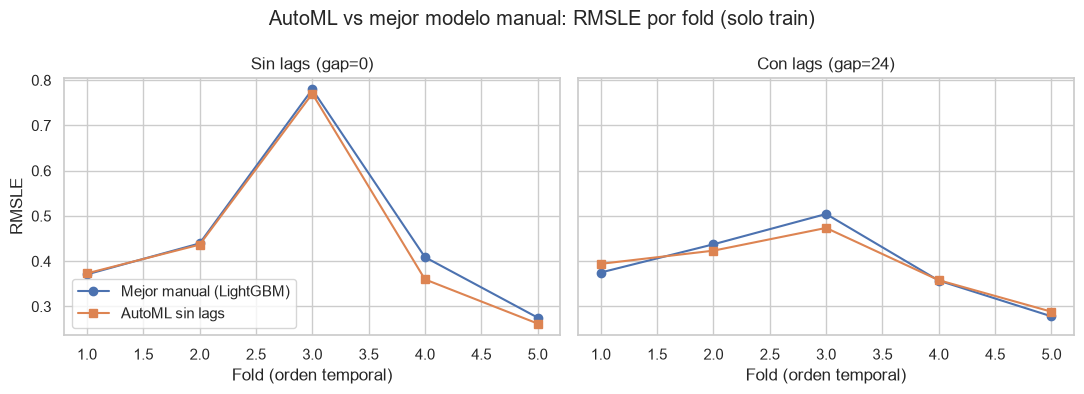

In [9]:
# Fold a fold: ¿en cuántos folds gana AutoML al mejor manual?
for via, man, pf in [("Sin lags", LGBM_TUN_FOLDS, pf_a), ("Con lags", LGBM_LAG_FOLDS, pf_b)]:
    d = np.array(man) - pf["rmsle"].to_numpy()          # > 0: AutoML mejor
    print(f"{via}: AutoML mejor en {int((d>0).sum())}/5 folds | diferencia media (manual − AutoML) = {d.mean():+.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (via, man, pf, t) in zip(axes, [("Sin lags (gap=0)", LGBM_TUN_FOLDS, pf_a, "AutoML sin lags"), ("Con lags (gap=24)", LGBM_LAG_FOLDS, pf_b, "AutoML con lags")]):
    ax.plot(range(1, 6), man, marker="o", label="Mejor manual (LightGBM)")
    ax.plot(range(1, 6), pf["rmsle"], marker="s", label=t)
    ax.set(title=via, xlabel="Fold (orden temporal)")
axes[0].set_ylabel("RMSLE"); axes[0].legend()
fig.suptitle("AutoML vs mejor modelo manual: RMSLE por fold (solo train)"); fig.tight_layout()
fig.savefig(FIG_DIR / "03_automl_vs_manual.png", dpi=130); plt.show()

### ✅ Punto de control 4
La comparación es justa si: mismos folds (`get_cv()` / `get_cv(gap=24)`), mismo target `log1p`, misma métrica, mismas variables y el mejor de AutoML re-evaluado con `validar_temporal`. Las cuatro condiciones se cumplen por construcción en este notebook.

## 6) Registro de la configuración y de la ejecución

In [10]:
reg = {
    "herramienta": "FLAML", "version_flaml": flaml.__version__, "version_sklearn": sklearn.__version__,
    "python": platform.python_version(), "so": platform.platform(),
    "seed": RANDOM_STATE, "time_budget_s": TIME_BUDGET, "estimator_list": ESTIMATORS,
    "metric": "rmse sobre log1p(cnt) (equivale a RMSLE)", "eval_method": "cv",
    "split_type": "TimeSeriesSplit de get_cv() (5 folds, ventana expansiva; gap=0 sin lags y gap=24 con lags)",
    "sin_lags": {**info_a, "reevaluacion_rmsle": res_a["rmsle_media"], "reevaluacion_std": res_a["rmsle_std"]},
    "con_lags": {**info_b, "reevaluacion_rmsle": res_b["rmsle_media"], "reevaluacion_std": res_b["rmsle_std"]},
}
with open(REP_DIR / "automl_config.json", "w", encoding="utf-8") as f:
    json.dump(reg, f, indent=2, ensure_ascii=False, default=str)
print(json.dumps(reg, indent=2, ensure_ascii=False, default=str)[:1800])

{
  "herramienta": "FLAML",
  "version_flaml": "2.7.0",
  "version_sklearn": "1.9.1",
  "python": "3.13.14",
  "so": "Windows-10-10.0.19045-SP0",
  "seed": 42,
  "time_budget_s": 300,
  "estimator_list": [
    "lgbm",
    "rf",
    "extra_tree"
  ],
  "metric": "rmse sobre log1p(cnt) (equivale a RMSLE)",
  "eval_method": "cv",
  "split_type": "TimeSeriesSplit de get_cv() (5 folds, ventana expansiva; gap=0 sin lags y gap=24 con lags)",
  "sin_lags": {
    "nombre": "AutoML sin lags",
    "mejor_estimador": "lgbm",
    "mejor_config": {
      "n_estimators": 2027,
      "num_leaves": 4,
      "min_child_samples": 18,
      "learning_rate": 0.07995219129498729,
      "log_max_bin": 8,
      "colsample_bytree": 0.7654968621694198,
      "reg_alpha": 2.8061780535782885,
      "reg_lambda": 0.1253123456265875
    },
    "rmse_log_cv_flaml": 0.4407482336518781,
    "tiempo_s": 302.2,
    "n_configuraciones": 12,
    "reevaluacion_rmsle": 0.440451470917557,
    "reevaluacion_std": 0.1946338203

## 7) Trade-offs AutoML vs manual (guía §3.6)

| Criterio | AutoML (FLAML) | Manual (LightGBM de Joan) |
| :--- | :--- | :--- |
| **Rendimiento** | Ver tabla de la sección 5 (se completa con los números reales del experimento). | Ver tabla de la sección 5. |
| **Tiempo** | Presupuesto fijo de `TIME_BUDGET` s por ejecución, sin trabajo humano durante la búsqueda. | ~300–350 s de búsqueda más horas de ablaciones y fichas de decisión. |
| **Interpretabilidad** | El modelo ganador es un ensamble de árboles; igual de (poco) interpretable que el manual, pero **no se sabe por qué** se eligió: la historia del proceso está en el log. | Cada decisión (tendencia, `windspeed`, Poisson, lags) tiene una ficha con evidencia. |
| **Control del proceso** | Bajo: elige el estimador y los hiperparámetros; no sabe del calendario, de los lags ni del problema del fold 3. | Alto: se decide qué se prueba y qué se descarta con la regla de adopción. |
| **Reproducibilidad** | Parcial: con `seed` fijo, pero el número de configuraciones probadas depende de la velocidad de la máquina por usar `time_budget`. Se registra la versión, el log y la cantidad de configuraciones. | Alta: semillas fijas y parámetros en `CONFIG`. |

**Conclusión metodológica:** AutoML es la referencia contra la que se comparan los modelos manuales; no los sustituye ni justifica por sí solo la elección del modelo final.